# Unsupervised Learning: K-Means Clustering

## 0. Setup and Configuration
Before training our K-Means model, we import the core scientific libraries and configure our data source. Use the code block below to either load your own dataset or default to a custom CSV file.

In [1]:
import numpy as np
import pandas as pd
import os

# --- Custom Dataset Configuration ---
# Configured with relative paths for seamless local VS Code and repo execution
USE_CUSTOM_DATA = True
DATASET_CANDIDATES = [
    os.path.join('..', 'datasets', 'student_performance.csv'),
    os.path.join('datasets', 'student_performance.csv'),
    'student_performance.csv',
    '/content/student_performance.csv'
]
DATASET_PATH = next((p for p in DATASET_CANDIDATES if os.path.exists(p)), DATASET_CANDIDATES[0])

if USE_CUSTOM_DATA:
    if os.path.exists(DATASET_PATH):
        # Load your dataset
        df_custom = pd.read_csv(DATASET_PATH)
        print(f"Loaded dataset from: {DATASET_PATH} with shape: {df_custom.shape}")
        display(df_custom.head())
    else:
        print(f"Warning: {DATASET_PATH} not found. Please verify dataset location.")
else:
    print("Using default synthetic data generator in Step 1.")


Loaded custom dataset with shape: (14003, 16)


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


## 1. Training and Predicting
In this section, we generate synthetic data, instantiate the `KMeans` model from `scikit-learn`, fit the model, and predict the cluster assignments.

In [2]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# 1. Determine data source dynamically
if 'USE_CUSTOM_DATA' in globals() and USE_CUSTOM_DATA and 'df_custom' in globals():
    print("Using custom dataset configured in Step 0.")
    df = df_custom.copy()
    # Select numeric features for clustering from the custom student dataset
    # Using actual column names: 'StudyHours' and 'ExamScore'
    X = df[["StudyHours", "ExamScore"]]
    if X.shape[1] < 2:
        raise ValueError("Custom dataset must contain at least 2 numerical features for this template.")
else:
    print("Using default synthetic data generator.")
    # Generate synthetic 2D data for demonstration
    X, y_true = make_blobs(n_samples=1000, centers=4, cluster_std=0.60, random_state=67)
    df = pd.DataFrame(X, columns=['StudyHours', 'ExamScore'])

# 2. Define and train the K-Means model
n_clusters = 4
model = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')

# 3. Fit and predict cluster assignments
df['Cluster'] = model.fit_predict(X)

# Dynamically extract centroid references for downstream steps
centroids = model.cluster_centers_

display(df.head())

Using custom dataset configured in Step 0.


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade,Cluster
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2,1
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2,1


## 2. Inspecting Created Clusters
Here, we examine the resulting cluster properties, including cluster centers (centroids) and the distribution of samples across clusters.

In [3]:
# 1. Inspect cluster centroids
centroids = model.cluster_centers_
centroids_df = pd.DataFrame(centroids, columns=['StudyHours', 'ExamScore'])
centroids_df.index.name = 'Cluster'
print("--- Cluster Centroids ---")
display(centroids_df)

# 2. Inspect size of each cluster
print("\n--- Sample Count per Cluster ---")
display(df['Cluster'].value_counts().sort_index().to_frame(name='Count'))

--- Cluster Centroids ---


,StudyHours,ExamScore
Cluster,,
0,20.130349,92.106851
1,19.923649,60.036031
2,19.868985,75.463143
3,20.012204,45.831241



--- Sample Count per Cluster ---


,Count
Cluster,
0,4043
1,3493
2,3595
3,2872


## 3. Visualizing the Results
We use `matplotlib` and `seaborn` to visualize the clusters along with their respective centroids.

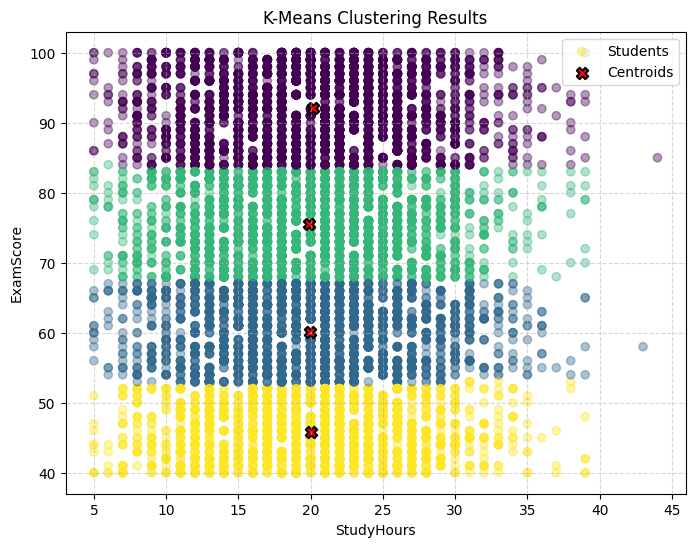

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Plot the data points colored by cluster using correct column names
plt.scatter(
    df["StudyHours"],
    df["ExamScore"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.4,
    label="Students"
)

# Plot cluster centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    s=67,
    marker='X',
    label='Centroids',
    edgecolors='black',
    linewidths=1.5
)

plt.title('K-Means Clustering Results')
plt.xlabel('StudyHours')
plt.ylabel('ExamScore')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
# Save visualization to results directory
os.makedirs(os.path.join('..', 'results', 'kmeans'), exist_ok=True)
os.makedirs(os.path.join('results', 'kmeans'), exist_ok=True)
save_path = os.path.join('..', 'results', 'kmeans', 'kmeans_results.png') if os.path.exists(os.path.join('..', 'results')) else os.path.join('results', 'kmeans', 'kmeans_results.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {save_path}")
plt.show()

## 4. Interpretation Guide for the Results

When evaluating your K-Means model, keep the following points in mind:

*   **Centroid Positioning:** The centroids (marked as red 'X's) represent the average (mean) values of all points belonging to that cluster. Use them to understand the profile or 'persona' of each cluster.
*   **Cluster Density and Shape:** K-Means assumes spherical clusters and equal variance. If your actual data contains elongated, irregular, or overlapping shapes, other algorithms like DBSCAN or Gaussian Mixture Models may be more appropriate.
*   **Choosing 'K' (Elbow Method):** In a real-world scenario, you can tune the number of clusters $K$ by plotting the Within-Cluster Sum of Squares (Inertia) against multiple values of $K$ and choosing the "elbow" point where the rate of decrease slows down.

## 5. Cluster Profiles and Strategic Business Decisions

Based on the resulting K-Means centroids ($K=4$), the student cohort is segmented into four distinct academic performance groups:

| Cluster | Cluster Label | Centroid (StudyHours, ExamScore) | Sample Count | Academic Profile |
| :---: | :---: | :---: | :---: | :--- |
| **0** | **High Achievers** | **(20.13, 92.11)** | 4,043 (28.9%) | Outstanding mastery; consistent study habits producing top-tier exam performance. |
| **1** | **Moderate / At-Risk** | **(19.92, 60.04)** | 3,493 (24.9%) | Average study investment but sub-optimal comprehension; struggling with core concepts. |
| **2** | **Good / Competent** | **(19.87, 75.46)** | 3,595 (25.7%) | Solid exam performance; reliable grasp of subjects with potential for honors. |
| **3** | **Underperforming / Critical** | **(20.01, 45.83)** | 2,872 (20.5%) | Despite ~20 study hours, achieving critically low scores; severe learning or engagement barrier. |

### Actionable Business & Institutional Decisions

#### Cluster 0: High Achievers
1. **Advanced Placement & Peer Mentorship**: Invite students into accelerated coursework, research projects, and paid peer-tutoring positions to foster institutional leadership.
2. **Honors & Scholarship Fast-Tracking**: Prioritize students for merit-based scholarships, national competitions, and direct industry internship pipelines.

#### Cluster 1: Moderate / At-Risk
1. **Diagnostic Formative Assessments**: Deploy bi-weekly targeted quizzes to pinpoint conceptual gaps in foundational topics before midterms.
2. **Study Methodology Workshops**: Provide specialized training on active recall, spaced repetition, and exam time management to convert study hours into higher retention.

#### Cluster 2: Good / Competent
1. **Targeted Grade Uplift Clinics**: Offer optional advanced problem-solving sessions focusing on high-difficulty exam questions to push scores from 75+ into the 90+ bracket.
2. **Engagement & Interactive Learning**: Integrate collaborative problem sets and digital simulation tools to boost conceptual mastery and enthusiasm.

#### Cluster 3: Underperforming / Critical
1. **Immediate Academic Intervention & Advising**: Issue early-alert warning notifications and mandate one-on-one academic counseling to assess underlying challenges (learning style mismatch, stress, or attendance gaps).
2. **Structured Remedial Bootcamp**: Enroll students into guided remedial tutoring cohorts with simplified learning modules, foundational concept reviews, and weekly progress tracking.
